# 3.2 Naive Bayes

Bayes' theorem, the "naive" conditional-independence assumption, and a
Gaussian model for continuous predictors -- applied to the same churn
target and features as every other classification notebook.

## Setup

Throughout this notebook (and every other notebook in this folder) we reuse
the **same 300-row synthetic customer table** (`data/customers.csv`, see
`data/generate_customers.py`): a small telecom/subscription dataset with a
continuous target (`monthly_spend`) for regression notebooks and a binary
target (`churned`) for classification notebooks, plus a block of numeric
features used for resampling, evaluation-metric, dimensionality-reduction
and clustering demos. The point isn't the dataset -- it's small and
synthetic on purpose -- the point is seeing each technique applied to
something you already recognise from the last notebook.

Every classification notebook predicts the **same target, from the same
features, on the same train/test split** -- so the confusion matrix/ROC/AUC
numbers below are directly comparable to the other technique notebooks in
this folder.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("common"))
sys.path.insert(0, os.path.abspath("../common"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

CUSTOMERS_PATH = "data/customers.csv" if os.path.exists("data/customers.csv") else "../data/customers.csv"
df = pd.read_csv(CUSTOMERS_PATH)
df.head()

,customer_id,age,region,tenure_months,income_k,monthly_usage,support_calls,discount_pct,satisfaction,monthly_spend,churned
0,C0001,45.7,South,90.7,78.1,8.3,2,0,8.12,39.35,0
1,C0002,29.5,North,54.9,58.4,27.3,6,5,5.80,51.69,0
2,C0003,51.0,West,28.6,73.3,13.9,5,0,5.48,37.75,1
3,C0004,53.3,West,22.9,106.5,13.3,6,10,9.25,34.31,1
4,C0005,18.6,West,45.7,35.5,67.2,6,15,7.26,52.28,0


In [2]:
from sklearn.model_selection import train_test_split
from plotting import plot_confusion, plot_roc, plot_lift

features = ["age","tenure_months","income_k","monthly_usage","support_calls","discount_pct","satisfaction"]
X = df[features]
y = df["churned"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
print("train:", Xtr.shape, " test:", Xte.shape, " churn rate (train/test):", round(ytr.mean(),3), round(yte.mean(),3))

train: (210, 7)  test: (90, 7)  churn rate (train/test): 0.338 0.344


## From Bayes' rule to a classifier

$$P(\text{churn} \mid x_1, \dots, x_p) \propto P(\text{churn}) \prod_{i=1}^{p} P(x_i \mid \text{churn})$$

The "naive" part: treat every feature as conditionally independent given
the class, so the joint likelihood collapses to a simple product -- a
strong assumption, rarely exactly true, but often good enough.

In [3]:
from sklearn.naive_bayes import GaussianNB

clf = GaussianNB().fit(Xtr, ytr)
print("Class priors P(churned):", dict(zip(clf.classes_, clf.class_prior_.round(3))))

Class priors P(churned): {np.int64(0): np.float64(0.662), np.int64(1): np.float64(0.338)}


## Modelling continuous predictors: choosing a fitting distribution

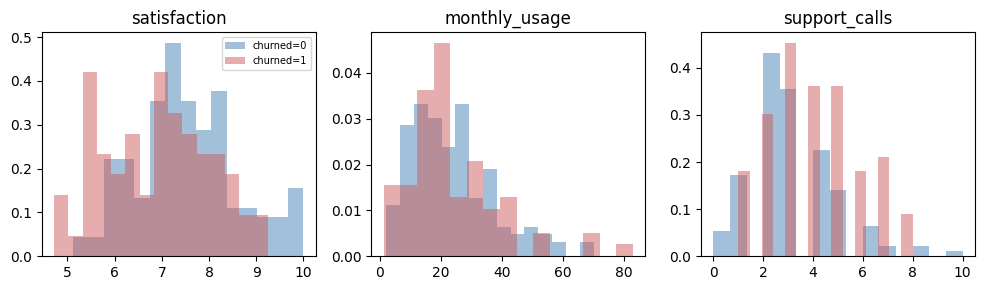

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, feat in zip(axes, ["satisfaction", "monthly_usage", "support_calls"]):
    for cls, color in zip([0, 1], ["steelblue", "indianred"]):
        vals = Xtr.loc[ytr == cls, feat]
        ax.hist(vals, bins=15, alpha=0.5, density=True, color=color, label=f"churned={cls}")
    ax.set_title(feat)
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

`GaussianNB` fits one Gaussian per feature per class -- reasonable when a
histogram like the ones above looks roughly bell-shaped and shifted between
classes (as `satisfaction` and `support_calls` do here); a skewed feature
would be a case for a different distribution, per the "choosing a
distribution that fits the data" slide.

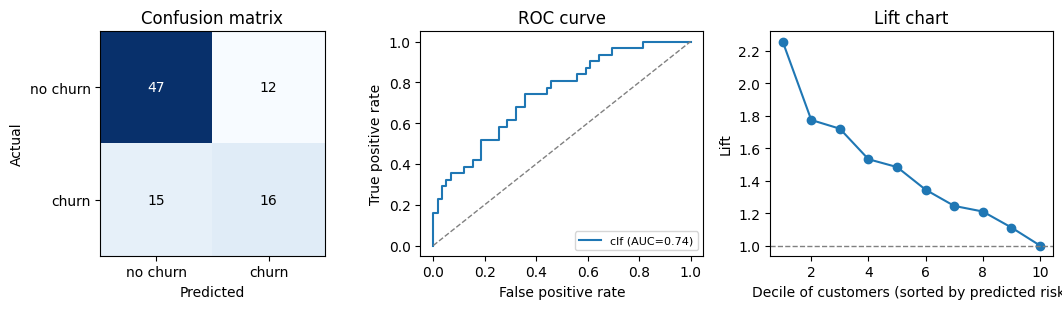

AUC: 0.741


In [5]:
y_pred = clf.predict(Xte)
y_score = clf.predict_proba(Xte)[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
plot_confusion(yte, y_pred, ax=axes[0])
auc_val = plot_roc(yte, y_score, ax=axes[1], label="clf")
plot_lift(yte, y_score, ax=axes[2])
plt.tight_layout(); plt.show()
print("AUC:", round(auc_val, 3))

**Wrap-up**: Naive Bayes is fast and often a solid baseline despite the
independence assumption -- compare its AUC/lift here directly against
logistic regression's, on the identical split.